In [1]:
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

In [2]:
X_train=pd.read_csv("../data/processed/X_train.csv")

In [3]:
X_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 3467 entries, 0 to 3466
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   memory_mib      3467 non-null   int64
 1   num_gpu         3467 non-null   int64
 2   gpu_milli       3467 non-null   int64
 3   duration_time   3467 non-null   int64
 4   qos_Burstable   3467 non-null   int64
 5   qos_Guaranteed  3467 non-null   int64
 6   qos_LS          3467 non-null   int64
dtypes: int64(7)
memory usage: 189.7 KB


In [9]:

#Cargamos los artefactos
model_nn=joblib.load("../models/model_nn.joblib")#Este es para la red neuronal
scaler=joblib.load("../models/scaler_nn.joblib")
model_lr=joblib.load("../models/model_lr.joblib")#Este es para la regresión lineal

#Cargamos los datos de prueba que serviran para los dos modelos
X_test=pd.read_csv("../data/processed/X_test.csv")
y_test=pd.read_csv("../data/processed/y_test.csv").squeeze()

#Escalamos los datos de prueba y hacemos predicciones
X_test_scaled=scaler.transform(X_test)
y_pred_nn=model_nn.predict(X_test_scaled)#Este es para la red neuronal
y_pred_lr=model_lr.predict(X_test)#Este es para la regresión lineal

In [ ]:
r2_lr=r2_score(y_test,y_pred_lr) #Este medira la precisión de la regresión lineal
r2_nn=r2_score(y_test,y_pred_nn) #Este medira la precisión de la red neuronal

In [2]:
plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid")

<Figure size 1400x600 with 0 Axes>

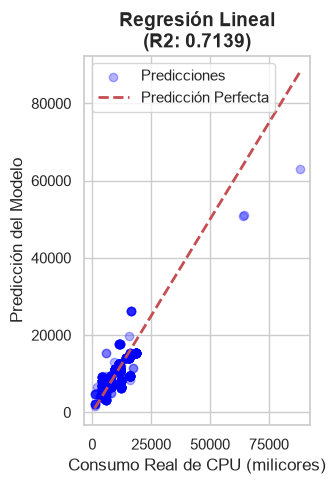

In [14]:
# Gráfico 1: Regresión Lineal
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_lr, alpha=0.3, color='blue', label='Predicciones')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Predicción Perfecta')
plt.title(f"Regresión Lineal\n(R2: {r2_lr:.4f})", fontsize=14, fontweight='bold')
plt.xlabel("Consumo Real de CPU (milicores)")
plt.ylabel("Predicción del Modelo")
plt.legend()

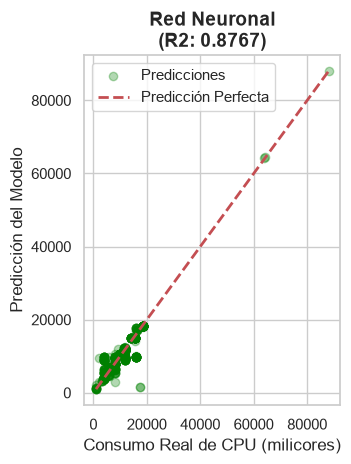

In [15]:
# Gráfico 2: Red Neuronal
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_nn, alpha=0.3, color='green', label='Predicciones')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Predicción Perfecta')
plt.title(f"Red Neuronal\n(R2: {r2_nn:.4f})", fontsize=14, fontweight='bold')
plt.xlabel("Consumo Real de CPU (milicores)")
plt.ylabel("Predicción del Modelo")
plt.legend()

plt.tight_layout()
plt.show()